/tmp/ipython-input-218579404.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start='2000-01-01')['Close']
[*********************100%***********************]  10 of 10 completed
/usr/local/lib/python3.12/dist-packages/pandas/core/nanops.py:1675: RuntimeWarning: Degrees of freedom <= 0 for slice
  return np.cov(a, b, ddof=ddof)[0, 1]
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2773: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2773: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)


Cumulative Return: 7.35
Sharpe Ratio: 0.50
Max Drawdown: -0.47
Strategy Beta: 0.90


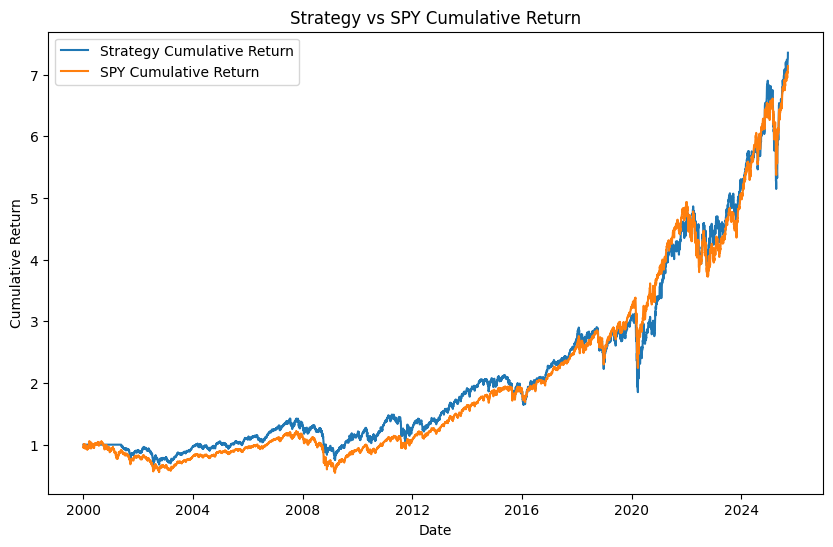

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Configuration variables
BETA_LOOKBACK_YEARS = 5
HOLDING_PERIOD_YEARS = 2

# Define sector ETFs
sectors = ['XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLU', 'XLV', 'XLY', 'XLB']

# Download data for SPY and sectors
tickers = ['SPY'] + sectors
data = yf.download(tickers, start='2000-01-01')['Close']

# Calculate daily returns
returns = data.pct_change().dropna()

# Convert years to trading days (approx 252 days per year)
beta_lookback_days = BETA_LOOKBACK_YEARS * 252
holding_period_days = HOLDING_PERIOD_YEARS * 252

# Initialize portfolio returns
port_returns = pd.Series(0.0, index=returns.index)
regime = pd.Series(index=returns.index, dtype='object')

# Rolling beta calculation and holding periods
current_idx = returns.index[0]
while current_idx < returns.index[-1]:
    # Define lookback period
    lookback_end = current_idx
    lookback_start = max(returns.index[0], lookback_end - pd.Timedelta(days=beta_lookback_days))

    # Compute betas for each sector
    betas = {}
    lookback_returns = returns.loc[lookback_start:lookback_end]
    for sec in sectors:
        cov = lookback_returns[sec].cov(lookback_returns['SPY'])
        var = lookback_returns['SPY'].var()
        betas[sec] = cov / var if var != 0 else 0

    # Classify sectors
    high_beta_sectors = [s for s in sectors if betas[s] > 1]
    low_beta_sectors = [s for s in sectors if betas[s] < 1]

    # Compute MAs for decision
    ma50 = data['SPY'].loc[lookback_start:lookback_end].rolling(50).mean()
    ma200 = data['SPY'].loc[lookback_start:lookback_end].rolling(200).mean()

    # Determine regime at lookback_end
    if pd.isna(ma50[lookback_end]) or pd.isna(ma200[lookback_end]):
        current_idx += pd.Timedelta(days=holding_period_days)
        continue
    current_regime = 'high' if ma50[lookback_end] > ma200[lookback_end] else 'low'

    # Apply regime for holding period
    holding_end = min(returns.index[-1], current_idx + pd.Timedelta(days=holding_period_days))
    holding_indices = returns.loc[current_idx:holding_end].index

    for dt in holding_indices:
        regime.loc[dt] = current_regime
        quals = high_beta_sectors if current_regime == 'high' else low_beta_sectors
        if quals:
            port_returns.loc[dt] = returns.loc[dt, quals].mean()

    current_idx += pd.Timedelta(days=holding_period_days)

# Cumulative return for strategy
cumulative_return = (1 + port_returns).cumprod()

# Cumulative return for SPY
spy_cumulative_return = (1 + returns['SPY']).cumprod()

# Sharpe ratio (assuming risk-free rate = 0, annualized)
mean_ret = port_returns.mean()
std_ret = port_returns.std()
sharpe = mean_ret / std_ret * np.sqrt(252) if std_ret != 0 else 0

# Max drawdown
drawdown = cumulative_return / cumulative_return.cummax() - 1
max_dd = drawdown.min()

# Calculate strategy beta with respect to the market (SPY)
cov_strat_market = port_returns.cov(returns['SPY'])
var_market = returns['SPY'].var()
strategy_beta = cov_strat_market / var_market if var_market != 0 else 0

print(f"Cumulative Return: {cumulative_return.iloc[-1]:.2f}")
print(f"Sharpe Ratio: {sharpe:.2f}")
print(f"Max Drawdown: {max_dd:.2f}")
print(f"Strategy Beta: {strategy_beta:.2f}")

# Plot cumulative returns together
plt.figure(figsize=(10, 6))
plt.plot(cumulative_return, label='Strategy Cumulative Return')
plt.plot(spy_cumulative_return, label='SPY Cumulative Return')
plt.title('Strategy vs SPY Cumulative Return')
plt.xlabel('Date')
plt.ylabel('Cumulative Return')
plt.legend()
plt.show()